<a href="https://colab.research.google.com/github/eparrama/S8-Project-NovaRetail/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


**NovaRetail+** es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y Retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ Causalidad.**


## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

In [86]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency

### Cargar Dataset

In [87]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/content/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [88]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` es numérica pero `flotante` debería ser `entera`


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [89]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [90]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [91]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


**Diagnóstico inicial de variables numéricas**

- `edad` — Tiene datos dentro de los rangos normales con edad mínima 18 y máxima 75, la media y la mediana son casi iguales por lo que no hay valores inválidos
- `nivel_ingreso` - Tiene valores dentro de un rango normal y no hay desviaciones fuertes, muy poca variación entre la media y la mediana
- `visitas_mes` - Al igual que las anteriores tiene muy bajo el diferencial entre media y mediana, siendo 1 la mínima y 25 la máxima
- `compras_mes` - Con un mínimo de compra en 0 y un máximo de 8 con la media y la mediana cercanas entre ellas
- `gasto_publicidad_dirigida` - Media (19.73) y medianas (20.15) cercanas y rangos dentro de lo normal
- `satisfaccion` - Media y mediana iguales (3.60) pues los rangos están acotados entre los valores 0 a 5
- `ingreso_anual` - La media es mayor a la mediana posiblemente causado por valores altos de ingreso pero dentro de los parámteros normales del negocio

#### Explorar variables binarias

In [92]:
# Verificar que cada columna tenga únicamente dos valores posibles
for col in ['miembro_premium', 'abandono']:
    print(col, df[col].unique())
    print(df[col].value_counts(normalize=True))

miembro_premium [0 1]
miembro_premium
0    0.860733
1    0.139267
Name: proportion, dtype: float64
abandono [0 1]
abandono
0    0.849267
1    0.150733
Name: proportion, dtype: float64


In [93]:
df[['miembro_premium', 'abandono']].nunique()

,0
miembro_premium,2
abandono,2


**Diagnóstico inicial de variables binarias**

- `miembro_premium` — Consta en su totalidad de solo 2 valores 0 y 1 por lo que es binaria
- `abandono` — Consta de solo 2 valores 0 y 1, también es binaria

#### Explorar variables categóricas

In [94]:
# Verificar el número de valores únicos por variable categórica
df[['tipo_dispositivo', 'region']].nunique()

,0
tipo_dispositivo,3
region,4


In [95]:
# Explorar variables categóricas y cómo se distribuyen
columnas_cat = ['tipo_dispositivo','region']
for col in columnas_cat :
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True)*100).round(2))

tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64
tipo_dispositivo
móvil         65.45
escritorio    24.80
tablet         9.75
Name: proportion, dtype: float64
region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64
region
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: proportion, dtype: float64


**Diagnóstico inicial de variables categóricas**

- `tipo_dispositivo` — Hay 3 valores que son móvil, escritorio y tablet, móvil es la que más registros tiene con 9,818
- `region` - Consta de 4 valores que son norte, oeste, sur y este, siendo el norte el que más incidencias tiene y el este las menos

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

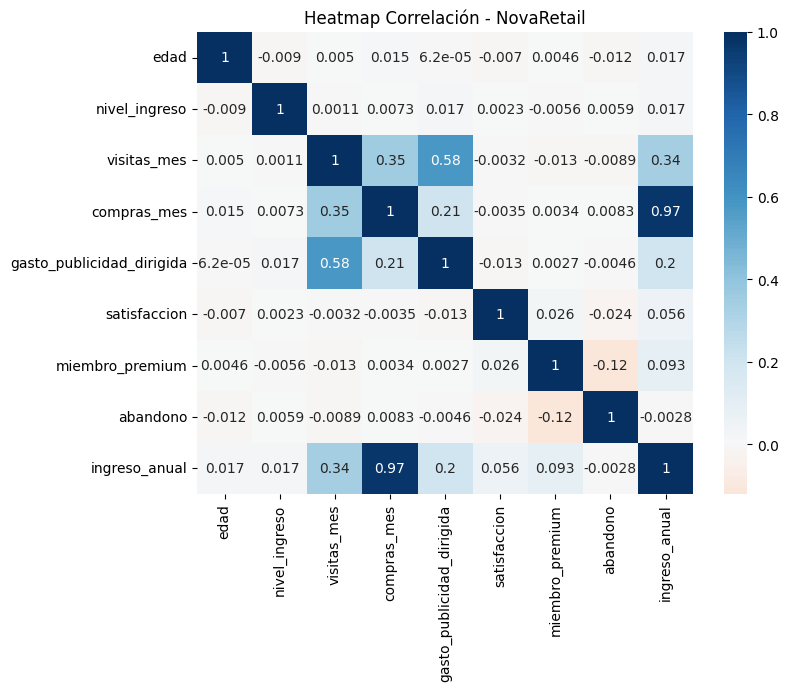

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizar la matriz de correlación para identificar relaciones
# Excluir columnas no numéricas como 'id_cliente'
corr = df.drop(columns=['id_cliente', 'tipo_dispositivo', 'region']).corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="RdBu", center=0)
plt.title("Heatmap Correlación - NovaRetail")
plt.savefig("heatmap_corr.png")
plt.show()

**Observaciones generales (Heatmap)**
- Se observa una relación **moderada positiva** entre `gasto_publicidad_dirigida` y `visitas_mes` y una relación **débil_positiva** del mismo con `compras_mes`. Hay una relación **débil negativa** entre `abandono` y `miembro_premium`, para las demás variables su relación es prácticamente nula

Observaciones respecto a `ingreso_anual`  
- Presenta una relación **fuerte positiva** con `compras_mes` y una relación **débil positiva** con `visitas_mes`, así mismo con `gasto_publicidad_dirigida`, con las demás variables prácticamente no hay relación


### Scatterplot general

Considero que **NO es necesario** visualizar un **scatterplot general** ya que las relaciones que vale la pena analizar de acuerdo al punto anterior son 2 o a lo mucho 5. Así mismo, si lo hiciéramos obtendríamos 81 gráficos que en vez clarificar la situación entre las variables nos haría más complicada la visualización y no contribuye a la claridad del reporte


### Scatterplot para pares clave

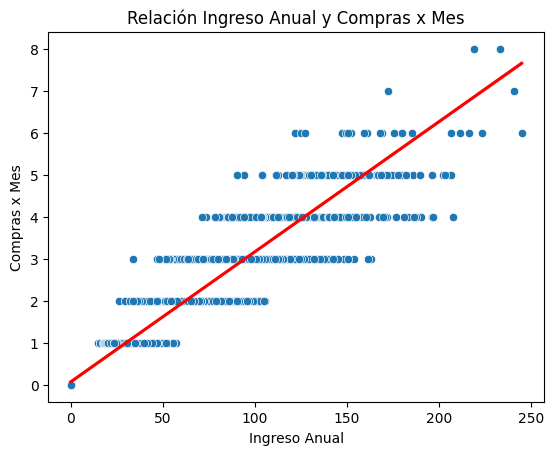

In [97]:

# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='ingreso_anual', y='compras_mes')
sns.regplot(data=df, x='ingreso_anual', y='compras_mes', scatter=False, color='red')
plt.title("Relación Ingreso Anual y Compras x Mes")
plt.xlabel("Ingreso Anual")
plt.ylabel("Compras x Mes")
plt.savefig("scatter_iacm.png")
plt.show()


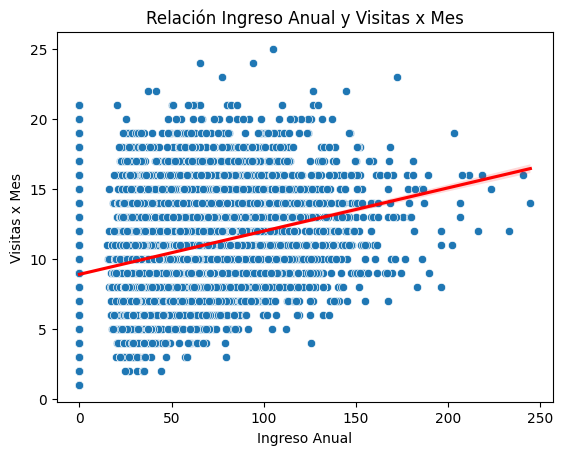

In [98]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='ingreso_anual', y='visitas_mes')
sns.regplot(data=df, x='ingreso_anual', y='visitas_mes', scatter=False, color='red')
plt.title("Relación Ingreso Anual y Visitas x Mes")
plt.xlabel("Ingreso Anual")
plt.ylabel("Visitas x Mes")
plt.savefig("scatter_iavm.png")
plt.show()


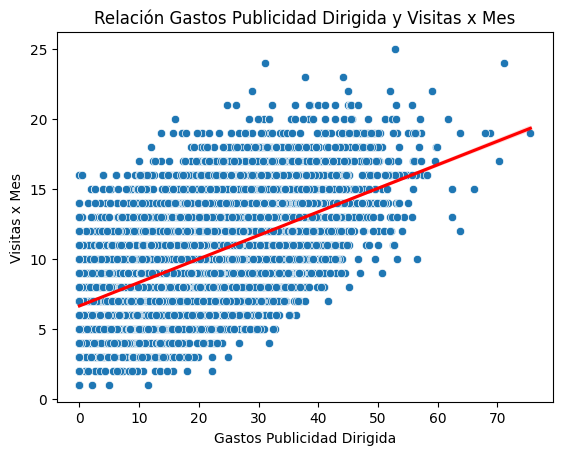

In [99]:
# Visualizar pares de variables con relaciones moderadas
sns.scatterplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes')
sns.regplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes' , scatter=False, color='red')
plt.title("Relación Gastos Publicidad Dirigida y Visitas x Mes")
plt.xlabel("Gastos Publicidad Dirigida")
plt.ylabel("Visitas x Mes")
plt.savefig("scatter_gpdvm.png")
plt.show()

**Observaciones iniciales (Scatterplot)**

**ingreso_anual vs compras_mes**
- Dirección Positiva
- Dispersión Baja
- Baja Presencia de Outliers se mantienen con la tendencia
- Posible Alta Colinealidad

**ingreso_anual vs visitas_mes**
- Dirección Positiva
- Dispersión Alta
- Presencia de Outliers Moderada
- Posible Colinealidad Baja o Nula

**gasto_publicidad_dirigida vs visitas_mes**
- Dirección Positiva
- Dispersión Media
- Presencia de Outliers media
- Posible Colinealidad pero moderada

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [100]:
# Calcular correlación entre variables relevantes Ingreso Anual y Compras x Mes
corr_pearson = df['ingreso_anual'].corr(df['compras_mes'], method='pearson')
corr_spearman = df['ingreso_anual'].corr(df['compras_mes'], method='spearman')

print(f"Correlación Pearson entre ingreso_anual y compras_mes: {corr_pearson:.2f}")
print(f"Correlación Spearman entre ingreso_anual y compras_mes: {corr_spearman:.2f}")

Correlación Pearson entre ingreso_anual y compras_mes: 0.97
Correlación Spearman entre ingreso_anual y compras_mes: 0.97


In [101]:
# Calcular correlación entre variables relevantes Ingreso Anual y Visitas x Mes
corr_pearson = df['ingreso_anual'].corr(df['visitas_mes'], method='pearson')
corr_spearman = df['ingreso_anual'].corr(df['visitas_mes'], method='spearman')

print(f"Correlación Pearson entre ingreso_anual y visitas_mes: {corr_pearson:.2f}")
print(f"Correlación Spearman entre ingreso_anual y visitas_mes: {corr_spearman:.2f}")

Correlación Pearson entre ingreso_anual y visitas_mes: 0.34
Correlación Spearman entre ingreso_anual y visitas_mes: 0.32


In [102]:
# Calcular correlación entre variables relevantes Gasto Publicidad Dirigida y Visitas x Mes
corr_pearson = df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='pearson')
corr_spearman = df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='spearman')
print(f"Correlación Pearson entre gasto_publicidad_dirigida y visitas_mes: {corr_pearson:.2f}")
print(f"Correlación Spearman entre gasto_publicidad_dirigida y visitas_mes: {corr_spearman:.2f}")

Correlación Pearson entre gasto_publicidad_dirigida y visitas_mes: 0.58
Correlación Spearman entre gasto_publicidad_dirigida y visitas_mes: 0.56


**Observaciones de correlación**

**ingreso_anual vs compras_mes**
- Correlación Positiva
- Magnitud Alta
- Posible Colinealidad
- Tanto Pearson como Spearman coinciden en valores

**ingreso_anual vs vistas_mes**
- Correlación Positiva
- Magnitud Débil
- Colinealidad Baja o Nula
- Tanto Pearson como Spearman coinciden en valores

**gasto_publicidad_dirigida vs visitas_mes**
- Correlación Positiva
- Magnitud Moderada
- No existe posible Colinealidad
- Tanto Pearson como Spearman coinciden en valores

### Punto-biserial

In [103]:
# Calcular correlación entre variables relevantes
res = pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
correlacion = res.statistic
print(f"Correlación Punto Biserial entre miembro_premium e ingreso_anual: {correlacion:.4f}")

res = pointbiserialr(df['abandono'], df['ingreso_anual'])
correlacion = res.statistic
print(f"Correlación Punto Biserial entre abandono e ingreso_anual: {correlacion:.4f}")

Correlación Punto Biserial entre miembro_premium e ingreso_anual: 0.0931
Correlación Punto Biserial entre abandono e ingreso_anual: -0.0028


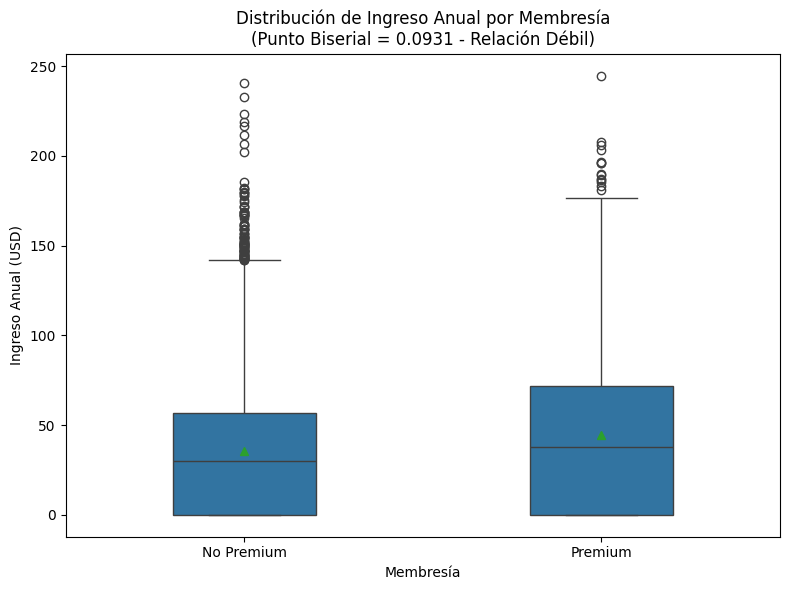

In [104]:
# Gráfico pointbserial
plt.figure(figsize=(8, 6))
df_temp = df.copy()
df_temp['miembro_premium_label'] = df_temp['miembro_premium'].map({0: 'No Premium', 1: 'Premium'})
sns.boxplot(
    data=df_temp,
    x='miembro_premium_label',
    y='ingreso_anual',
    width=0.4,
    showmeans=True)
plt.title("Distribución de Ingreso Anual por Membresía\n(Punto Biserial = 0.0931 - Relación Débil)")
plt.xlabel("Membresía")
plt.ylabel("Ingreso Anual (USD)")
plt.tight_layout()
plt.savefig("boxplot_pi.png")
plt.show()

**Observaciones Punto-biserial**

**miembro_premium vs ingreso_anual**
- No hay Relación o es una relación muy débil ya que su valor es 0.093 positiva

**abandono vs ingreso_anual**
- No existe Relación pues es prácticamente 0 (-0.0028) por lo tanto negativa

### V de Cramér

In [105]:
# Función para calcular V de Cramér
def cramer_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n = tabla.values.sum()
    coef_v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
    print(f"V de Cramer ({col1} vs {col2}): {coef_v:.4f}")


In [106]:
# Aplicar V de Cramér en variables relevantes tipo_dispositivo y region
col1 = 'tipo_dispositivo'
col2 = 'region'
cramer_v(df, col1, col2)

V de Cramer (tipo_dispositivo vs region): 0.0124


In [107]:
# Aplicar V de Cramér en variables relevantes tipo_dispositivo y abandono
col1 = 'tipo_dispositivo'
col2 = 'abandono'
cramer_v(df, col1, col2)

V de Cramer (tipo_dispositivo vs abandono): 0.0072


In [108]:
# Aplicar V de Cramér en variables relevantes abandono y region
col1 = 'region'
col2 = 'abandono'
cramer_v(df, col1, col2)

V de Cramer (region vs abandono): 0.0154


In [109]:
# Aplicar V de Cramér en variables relevantes abandono y miembro_premium
col1 = 'miembro_premium'
col2 = 'abandono'
cramer_v(df, col1, col2)

V de Cramer (miembro_premium vs abandono): 0.1202


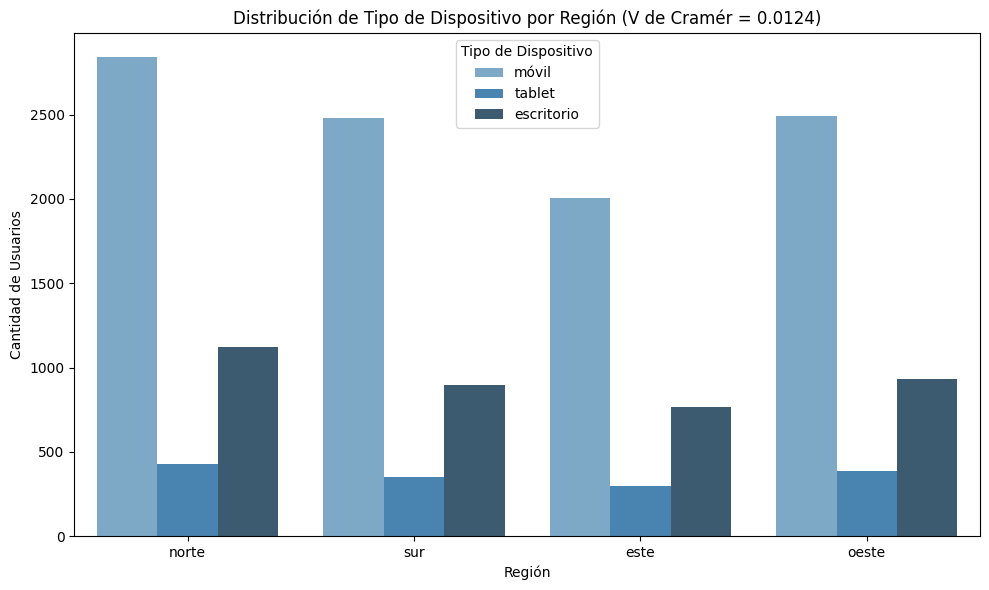

In [110]:
# Gráfico de barras agrupadas V de Cramér
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='region', hue='tipo_dispositivo', palette='Blues_d'
)
plt.title("Distribución de Tipo de Dispositivo por Región (V de Cramér = 0.0124)")
plt.xlabel("Región")
plt.ylabel("Cantidad de Usuarios")
plt.legend(title="Tipo de Dispositivo")
plt.tight_layout()
plt.savefig("barras_tdr.png")
plt.show()

**Observaciones V de Cramér**  
No existe relación entre **tipo_dispositivo y región** ya que **V de Cramér** es de solo `0.0124`


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo incluye:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### 5.1 Hallazgo 1 — Relación entre Ingreso Anual vs Compras x Mes

**Evidencia visual:**  El Heatmap de todas las variables numéricas nos presenta la correlación entre las 2 variables como fuerte y positiva, la cual se confirma al hacer su scatterplot y además prácticamente sin outliers

**Evidencia numérica:** Tanto Pearson como Spearman confirman esta alta correlación positiva, ambas con valores arriba de 0.97  

**Interpretación**  Es evidente que entre más compras por mes hay un mayor ingreso anual, la relación es marcadamente lineal y no se ve distorsionada por valores atípicos (outliers) o transformaciones no lineales. Utilizar ambas variables como predictores dentro de un modelo de regresión lineal causaría problemas de multicolinealidad por lo que se deberá ser cuidadoso y usarse una sola de ellas.


**No podemos afirmar**  Que una sea causa de la otra por lo que incentivar compras haga que un usuario genere automáticamente cierto volumen de ingresos sin considerar el valor promedio de ticket.
Tampoco se puede asumir causalidad en un solo sentido sin analizar el comportamiento temporal o la recurrencia real durante todo el año.


**Implicación de negocio**  La variable compras_mes sirve como un indicador del valor del cliente por lo que se deberán promover estrategias de conversión que incentiven la frecuencia de compra (programas de lealtad, ofertas por volumen o envíos gratis) está alineado directamente con el segmento de mayor valor económico para **NovaRetail+**.



### 5.2 Hallazgo 2 — Relación entre Ingreso Anual vs Visitas x Mes

**Evidencia visual:** El Heatmap nos indica una correlación débil y positiva, la cual se confirma al hacer su scatterplot el cual también nos muestra  presencia moderada de outliers

**Evidencia numérica:** Tanto Pearson como Spearman confirman esta débil correlación positiva con valores de 0.34 y 0.32 respectivamente

**Interpretación** Existe una relación positiva pero débil o moderada entre la frecuencia de visitas mensuales y el ingreso anual generado. Aunque los usuarios con mayor ingreso tienden a visitar la plataforma con más frecuencia, la alta dispersión de los datos indica que navegar activamente no se traduce necesariamente en compras directas de alto valor.

**No podemos afirmar** Que incrementar artificialmente las visitas a la plataforma (por ejemplo, mediante notificaciones masivas o recordatorios constantes) vaya a aumentar automáticamente los ingresos anuales. Tampoco se puede asumir que una baja cantidad de visitas implique un cliente de poco valor, ya que existen usuarios que realizan compras de alto ticket en pocas sesiones.

**Implicación de negocio** Las visitas deben tratarse como un indicador de tráfico e interés, pero no como una métrica final de rendimiento financiero. La estrategia del equipo de Crecimiento y Retención de **NovaRetail+** no debe centrarse solo en generar impresiones o clics en la app, sino en optimizar la tasa de conversión (funnel de ventas) para transformar esas visitas casuales en transacciones reales.

### 5.3 Hallazgo 3 — Relación entre Gasto Publicidad Dirigida vs Visitas x Mes

**Evidencia visual:**  El Heatmap muestra la correlación entre las 2 variables como moderada y positiva, la cual se confirma al hacer su scatterplot y con presencia media de outliers

**Evidencia numérica:** Tanto Pearson como Spearman nos confirman esta correlación positiva, con valores de 0.58 y 0.56 respectivamente

**Interpretación** Existe una correlación positiva moderada entre el gasto en publicidad dirigida a un usuario y el número de visitas que realiza a la plataforma en el mes. El hecho de que ambos coeficientes sean muy similares indica que la relación es bastante estable, sin ser distorsionada por outliers o un comportamiento no lineal extremo. Estas dos variables comparten suficiente variabilidad propia como para poder incluirse juntas dentro de un mismo modelo predictivo sin distorsionar los coeficientes por colinealidad.

**No podemos afirmar** que incrementar el presupuesto publicitario provocará un aumento directo y proporcional en el tráfico de cada usuario. Tampoco implica que más visitas se traduzcan directamente en compras finalizadas o mayores ingresos.

**Implicación de negocio** Los datos muestran que a mayor inversión de **NovaRetail+** en anuncios dirigidos por cliente, mayor tiende a ser la frecuencia de visitas mensuales. La publicidad dirigida cumple de forma consistente su rol de atraer e incentivar el tráfico de los usuarios.


### 5.4 Hallazgo 4 — Relación entre Ingreso Anual vs Miembro Premium

**Evidencia visual:**  Aunque en el Heatmap muestra la correlación entre las 2 variables como débil positiva (0.093), decidí mostrar este hallazgo para descartar la correlación entre ambas variables, así mismo adjunto boxplot donde podemos ver que la diferencia de aportación al ingreso anual entre miembros premium y los que no lo son es mínima

**Evidencia numérica:** Al analizar con Pointbiserial se confirma que esta correlación es débil positiva, conservando el valor de 0.0931

**Interpretación** Pertenecer a la membresía Premium explica menos del 1% de la variabilidad en los ingresos anuales que un usuario genera para la empresa. Aunque el signo es positivo (los usuarios premium gastan marginalmente más), la diferencia de consumo promedio entre tener o no la membresía no es estadísticamente relevante ni determinante dentro del volumen general de ventas de la plataforma.

**No podemos afirmar** que la suscripción Premium sea inútil o que no aporte valor, ya que podría estar generando beneficios en otras métricas como retención  o fidelidad con un bajo abandono, que no se reflejan directamente en esta correlación de ingresos anuales.

**Implicación de negocio** El equipo de Crecimiento y Retención de **NovaRetail+** debe revisar los beneficios actuales del programa Premium. Si no está impulsando un valor económico superior por cliente, los incentivos actuales podrían no ser suficientes o atractivos para motivar un mayor gasto.
Enfocar el presupuesto publicitario en vender membresías Premium no garantiza un incremento directo en el ingreso_anual por lo que las campañas deben centrarse en incentivar la frecuencia de compra directa (compras_mes), independientemente de la clasificación del usuario.


### 5.5 Hallazgo 5 — Relación entre Tipo Dispositivo vs Región/Abandono; Abandono vs Región/Miembro Premium con V de Cramér

**Evidencia visual:**  En la gráfica observamos que la distribución del tipo de dispositivo se mantiene uniforme en las 4 diferentes regiones

**Evidencia numérica:** Al analizar con V de Cramér las 4 correlaciones  encontramos lo siguiemte:  
- Tipo Dispositivo vs Región: No hay asociación, su valor es 0.0124  
- Tipo Dispositivo vs Abandono: No hay asociación, su valor es 0.0072  
- Abandono vs Región: No hay asociación, su valor es 0.0154  
- Abandono vs Miembro Premium: No hay asociación, su valor es 0.01202

**Interpretación**  
- Tipo Dispositivo vs Región: La elección del dispositivo por parte del usuario (móvil, escritorio o tablet) es completamente independiente de la región geográfica (norte, sur, este u oeste) en la que se encuentra.  
- Tipo Dispositivo vs Abandono: No existe ninguna relación entre la plataforma que usa el cliente y la probabilidad de que abandone **NovaRetail+**. La tasa de deserción es homogénea sin importar si acceden desde móvil, escritorio o tablet.  
- Abandono vs Región: La deserción de clientes se distribuye de manera uniforme a lo largo de la zona geográfica, mostrando una independencia casi total respecto a la ubicación del usuario.
- Abandono vs Miembro Premium: Existe una asociación positiva pero débil entre estar suscrito a la membresía Premium y la tasa de abandono.  

**No podemos afirmar**   
- Tipo Dispositivo vs Región: Que las preferencias tecnológicas o el acceso a infraestructura de internet varíen por zona geográfica dentro del perfil de clientes.  
- Tipo Dispositivo vs Abandono: Que la tasa de abandono esté motivada por fallas técnicas específicas, mala usabilidad o errores de plataforma en un dispositivo en particular.   
- Abandono vs Región: Que existan problemas de logística, tiempo de entrega o satisfacción localizada que estén provocando una mayor pérdida de clientes en una región específica.  
- Abandono vs Miembro Premium: Que ser usuario Premium reduzca significativamente la probabilidad de abandonar la plataforma, ni que el programa de membresía funcione actualmente como un mecanismo sólido de fidelización a largo plazo.

**Implicación de negocio**   
- Tipo Dispositivo vs Región: Evitar segmentar presupuestos de campañas publicitarias cruzando región con tipo de dispositivo, enfocando el esfuerzo en métricas que sí impacten el negocio.  
- Tipo Dispositivo vs Abandono: El equipo de Retención no debe gastar recursos auditando o rediseñando una plataforma específica con la intención de reducir el churn. Los motivos de abandono responden a factores transversales del servicio (precios, catálogo, soporte), no a la plataforma de acceso.   
- Abandono vs Región: Las iniciativas contra el abandono deben plantearse a nivel global y no mediante campañas aisladas de rescate por zonas geográficas. La retención responde a la propuesta de valor general de **NovaRetail+**.   
- Abandono vs Miembro Premium: El programa Premium requiere una revisión estratégica en sus beneficios percibidos. El equipo de Crecimiento debe reestructurar los incentivos y recompensas del plan para asegurar que generen una verdadera lealtad y retención en la base de clientes clave.  

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- El análisis indica Correlación no Causalidad, asumir causalidad nos puede llevar a decisiones de negocio erróneas
- Posibles efectos de segmentación no explorados
- No se puede evaluar la estacionalidad ni la evolución del comportamiento del cliente a lo largo de varios meses al ser evaluado anualmente
- Las compras por mes no nos dan un valor de ticket, al no contar con dicho dato no podemos saber si los miembros premium gastan más (o no) por compra no importando la frecuencia

### **Próximos pasos**

- Dado que no se pudo establecer causalidad se recomienda implementar un A/B testing (Experimento Controlado) para superar la limitación de la correlación
  
- Probar segmentación adicional:
  - Con gastos de publicidad dirigida vs visitas por mes segmentado por tipo de suscripción (miembro premium)
  - Ingreso Anual vs Compras x Mes segmentado por región y/o tipo de dispositivo
- Agregar la información al dataset de fechas de compra para poder establecer estacionalidad y así descartar o considerar sus efectos

- Así mismo agregar información (precio y cantidades) para obtener un valor de ticket o ingresarlo directamente para poder determinar compras por tipo de cliente en los ingresos anuales

- Para verificar el retorno de la inversión, se debe evaluar la conversión final de visitas y/o compras en ingresos.

- El programa Premium requiere una revisión estratégica en sus beneficios percibidos. El equipo de Crecimiento debe reestructurar los incentivos y recompensas del plan para asegurar que generen una verdadera lealtad y retención en la base de clientes clave.